# LAB | Feature Engineering

**Load the data**

In this challenge, we will be working with the same Spaceship Titanic data, like the previous Lab. The data can be found here:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv

Metadata

https://github.com/data-bootcamp-v4/data/blob/main/spaceship_titanic.md

In [2]:
#Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [3]:
spaceship = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv")
spaceship.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


**Check the shape of your data**

In [51]:
#your code here
spaceship.shape

(8693, 14)

**Check for data types**

In [6]:
#your code here
spaceship.dtypes

PassengerId         str
HomePlanet          str
CryoSleep        object
Cabin               str
Destination         str
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name                str
Transported        bool
dtype: object

**Check for missing values**

In [7]:
#your code here
spaceship.isna().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

There are multiple strategies to handle missing data

- Removing all rows or all columns containing missing data.
- Filling all missing values with a value (mean in continouos or mode in categorical for example).
- Filling all missing values with an algorithm.

For this exercise, because we have such low amount of null values, we will drop rows containing any missing value. 

In [52]:
#your code here
# Drops any row containing at least one NaN value

spaceship_clean = spaceship.dropna().copy()

# Check how many rows you lost:
print("Original rows:", len(spaceship))
print("Remaining rows:", len(spaceship_clean))

Original rows: 8693
Remaining rows: 6606


In [38]:
spaceship_clean.info()

<class 'pandas.DataFrame'>
Index: 6606 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   6606 non-null   str    
 1   HomePlanet    6606 non-null   str    
 2   CryoSleep     6606 non-null   object 
 3   Cabin         6606 non-null   str    
 4   Destination   6606 non-null   str    
 5   Age           6606 non-null   float64
 6   VIP           6606 non-null   object 
 7   RoomService   6606 non-null   float64
 8   FoodCourt     6606 non-null   float64
 9   ShoppingMall  6606 non-null   float64
 10  Spa           6606 non-null   float64
 11  VRDeck        6606 non-null   float64
 12  Name          6606 non-null   str    
 13  Transported   6606 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1017.8+ KB


In [53]:
spaceship_clean.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported'],
      dtype='str')

**Perform Train Test Split**

In [54]:
from sklearn.model_selection import train_test_split

features = spaceship_clean.drop(columns = ["Transported"])
target = spaceship_clean["Transported"]
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.20, random_state=42)

- **Cabin** is too granular - transform it in order to obtain {'A', 'B', 'C', 'D', 'E', 'F', 'G', 'T'}

In [55]:
#your code here
# Extract the first letter before the slash to get the Deck
spaceship_clean['Cabin'] = spaceship_clean['Cabin'].str.split('/').str[0]
spaceship_clean.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


- Drop PassengerId and Name

In [56]:
#your code here
spaceship_clean = spaceship_clean.drop(columns=['PassengerId', 'Name'])
spaceship_clean.head()

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
0,Europa,False,B,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False
1,Earth,False,F,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True
2,Europa,False,A,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False
3,Europa,False,A,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False
4,Earth,False,F,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True


- For non-numerical columns, do dummies.

In [60]:
import pandas as pd
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

# 1. Build the preprocessor without dropping any baseline categories
preprocessor = make_column_transformer(
    (
        
        OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
        make_column_selector(dtype_include=["object", "category"]),
    ),
    (
        # Converts True/False target into 1/0
        FunctionTransformer(
            lambda x: x.astype(int), feature_names_out="one-to-one"
        ),
        ["Transported"],
    ),
    remainder="passthrough",
    verbose_feature_names_out=False,
)

# 2. Transform the data and reconstruct the clean DataFrame
spaceship_clean = pd.DataFrame(
    preprocessor.fit_transform(spaceship_clean),
    columns=preprocessor.get_feature_names_out(),
)


In [68]:
#your code here
spaceship_clean.head()

,Transported,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,CryoSleep_False,CryoSleep_True,Cabin_A,Cabin_B,Cabin_C,Cabin_D,...,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,VIP_False,VIP_True,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,39.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,24.0,109.0,9.0,25.0,549.0,44.0
2,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,58.0,43.0,3576.0,0.0,6715.0,49.0
3,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,33.0,0.0,1283.0,371.0,3329.0,193.0
4,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,16.0,303.0,70.0,151.0,565.0,2.0


In [67]:
spaceship_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 6606 entries, 0 to 6605
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Transported                6606 non-null   float64
 1   HomePlanet_Earth           6606 non-null   float64
 2   HomePlanet_Europa          6606 non-null   float64
 3   HomePlanet_Mars            6606 non-null   float64
 4   CryoSleep_False            6606 non-null   float64
 5   CryoSleep_True             6606 non-null   float64
 6   Cabin_A                    6606 non-null   float64
 7   Cabin_B                    6606 non-null   float64
 8   Cabin_C                    6606 non-null   float64
 9   Cabin_D                    6606 non-null   float64
 10  Cabin_E                    6606 non-null   float64
 11  Cabin_F                    6606 non-null   float64
 12  Cabin_G                    6606 non-null   float64
 13  Cabin_T                    6606 non-null   float64
 14  Des

**Model Selection**

In this exercise we will be using **KNN** as our predictive model.

In [ ]:
from sklearn.model_selection import train_test_split

features = spaceship_clean.drop(columns = ["Transported"])
target = spaceship_clean["Transported"]
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.20, random_state=42)

In [94]:
#your code here
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the KNN Classifier (using baseline 5 neighbors)
knn = KNeighborsClassifier(n_neighbors=5)

# 2. Fit the model on the training data
knn.fit(X_train, y_train)

# 3. Predict on the test data
y_pred = knn.predict(X_test)

# 4. Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.7844175491679274


- Evaluate your model's performance. Comment it

Overall Test Accuracy: 0.7844



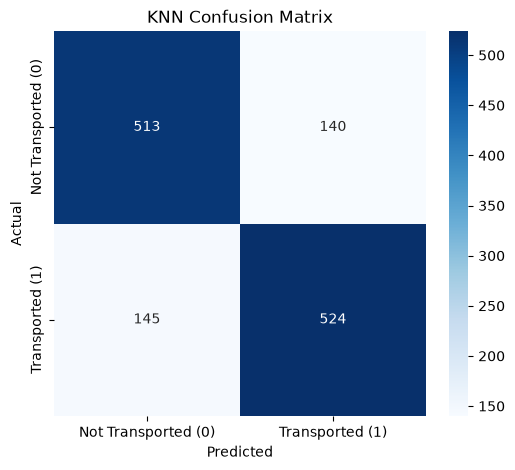

In [95]:
#your code here
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)


print(f"Overall Test Accuracy: {accuracy:.4f}\n")


# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Not Transported (0)', 'Transported (1)'], 
            yticklabels=['Not Transported (0)', 'Transported (1)'])
plt.title('KNN Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()
